In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.utils.path import DATA_DIR

# Load data

In [ ]:

cols = [
    "applicant_sex",
    "income",
    "loan_amount",
    "loan_purpose",
    "lien_status",
    "loan_type",
    "derived_race",
    "action_taken" #Target
]
df_2023 = pd.read_csv(f"{DATA_DIR}/raw/state_NY_2023.csv")
df_2023 = df_2023[cols].dropna(subset=cols)

df_2024 = pd.read_csv(f"{DATA_DIR}/raw/state_NY_2024.csv")
df_2024 = df_2024[cols].dropna(subset=cols)


# Preprocess

loại giá trị not applicable (Đây là các khoản vay của "Pháp nhân", không phải "Con người"). chỉ giữ giới tính 1: male, 2: female

In [108]:
df_2023 = df_2023[~df_2023["loan_purpose"].isin([5])]
df_2024 = df_2024[~df_2024["loan_purpose"].isin([5])]

df_2023 = df_2023[df_2023["applicant_sex"].isin([1, 2])]
df_2024 = df_2024[df_2024["applicant_sex"].isin([1, 2])]

Map cho các giá trị theo số thứ tự, nhìn cho đẹp chứ k có tác dụng vì t bị ocd

In [109]:
df_2023["loan_purpose"] = df_2023["loan_purpose"].map({
    1: 1,
    2: 2,
    31: 0,
    32: 3,
    4: 4,
})

df_2024["loan_purpose"] = df_2024["loan_purpose"].map({
    1: 1,
    2: 2,
    31: 0,
    32: 3,
    4: 4
})
""" 
Sau khi map
0 - Refinancing
1 - Home purchase
2 - Home improvement
3 - Cash-out refinancing
4 - Other purpose
"""

' \nSau khi map\n0 - Refinancing\n1 - Home purchase\n2 - Home improvement\n3 - Cash-out refinancing\n4 - Other purpose\n'

### Binary encoding derived_race
Black or African American: 1,
White: 0

In [110]:
target_races = ['Black or African American', 'White']
race_mapping = {'Black or African American': 1, 'White': 0}
df_2023 = df_2023[df_2023['derived_race'].isin(target_races)]
df_2024 = df_2024[df_2024['derived_race'].isin(target_races)]
df_2023['derived_race'] = df_2023['derived_race'].map(race_mapping)
df_2024['derived_race'] = df_2024['derived_race'].map(race_mapping)


### Binary encoding action_take (target)
0: Accepted, 1: Denied

In [111]:
df_2023 = df_2023[df_2023["action_taken"].isin([1, 2, 3])]
df_2024 = df_2024[df_2024["action_taken"].isin([1, 2, 3])]
df_2023["action_taken"] = df_2023["action_taken"].map({
    1: 0,  # Accepted
    2: 0,  # Accepted
    3: 1   # Denied
})

df_2024["action_taken"] = df_2024["action_taken"].map({
    1: 0,  # Accepted
    2: 0,  # Accepted
    3: 1   # Denied
})

### Visualize số lượng class

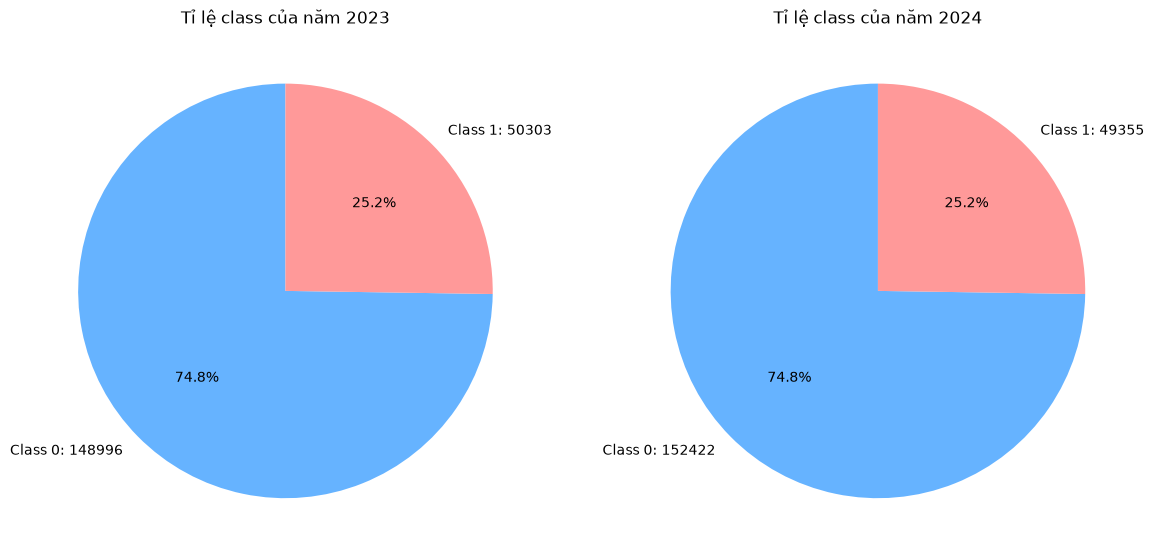

In [112]:
counts_2023 = df_2023["action_taken"].value_counts()
counts_2024 = df_2024["action_taken"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].pie(
    counts_2023.values,
    labels=[f"Class {counts_2023.index[0]}: {counts_2023[0]}", f"Class {counts_2023.index[1]}: {counts_2023[1]}"],
    autopct='%1.1f%%', 
    startangle=90,
    colors=['#66b3ff', '#ff9999'], # Xanh cho 0, Đỏ/Hồng cho 1 (tùy bạn chọn)
)             
axes[0].set_title("Tỉ lệ class của năm 2023")


axes[1].pie(
    counts_2023.values,
    labels=[f"Class {counts_2024.index[0]}: {counts_2024[0]}", f"Class {counts_2024.index[1]}: {counts_2024[1]}"],
    autopct='%1.1f%%', 
    startangle=90,
    colors=['#66b3ff', '#ff9999'], # Xanh cho 0, Đỏ/Hồng cho 1 (tùy bạn chọn)
)             
axes[1].set_title("Tỉ lệ class của năm 2024")

plt.tight_layout()
plt.show()

=> class mất cân bằng rất nhẹ 3:1

### Visualize income, loan_amount. Dùng sign * np.log1p(abs()) để đưa về pp chuẩn

In [113]:
income_raw_2023 = df_2023["income"]
loan_amount_raw_2023 = df_2023["loan_amount"]

income_processed = np.sign(income_raw_2023) * np.log1p(np.abs(income_raw_2023))
loan_amount_processed = np.sign(loan_amount_raw_2023) * np.log1p(np.abs(loan_amount_raw_2023))

In [114]:
loan_amount_processed.describe()

count    199299.000000
mean         11.998494
std           1.019881
min           8.517393
25%          11.225257
50%          12.013707
75%          12.751303
max          17.785897
Name: loan_amount, dtype: float64

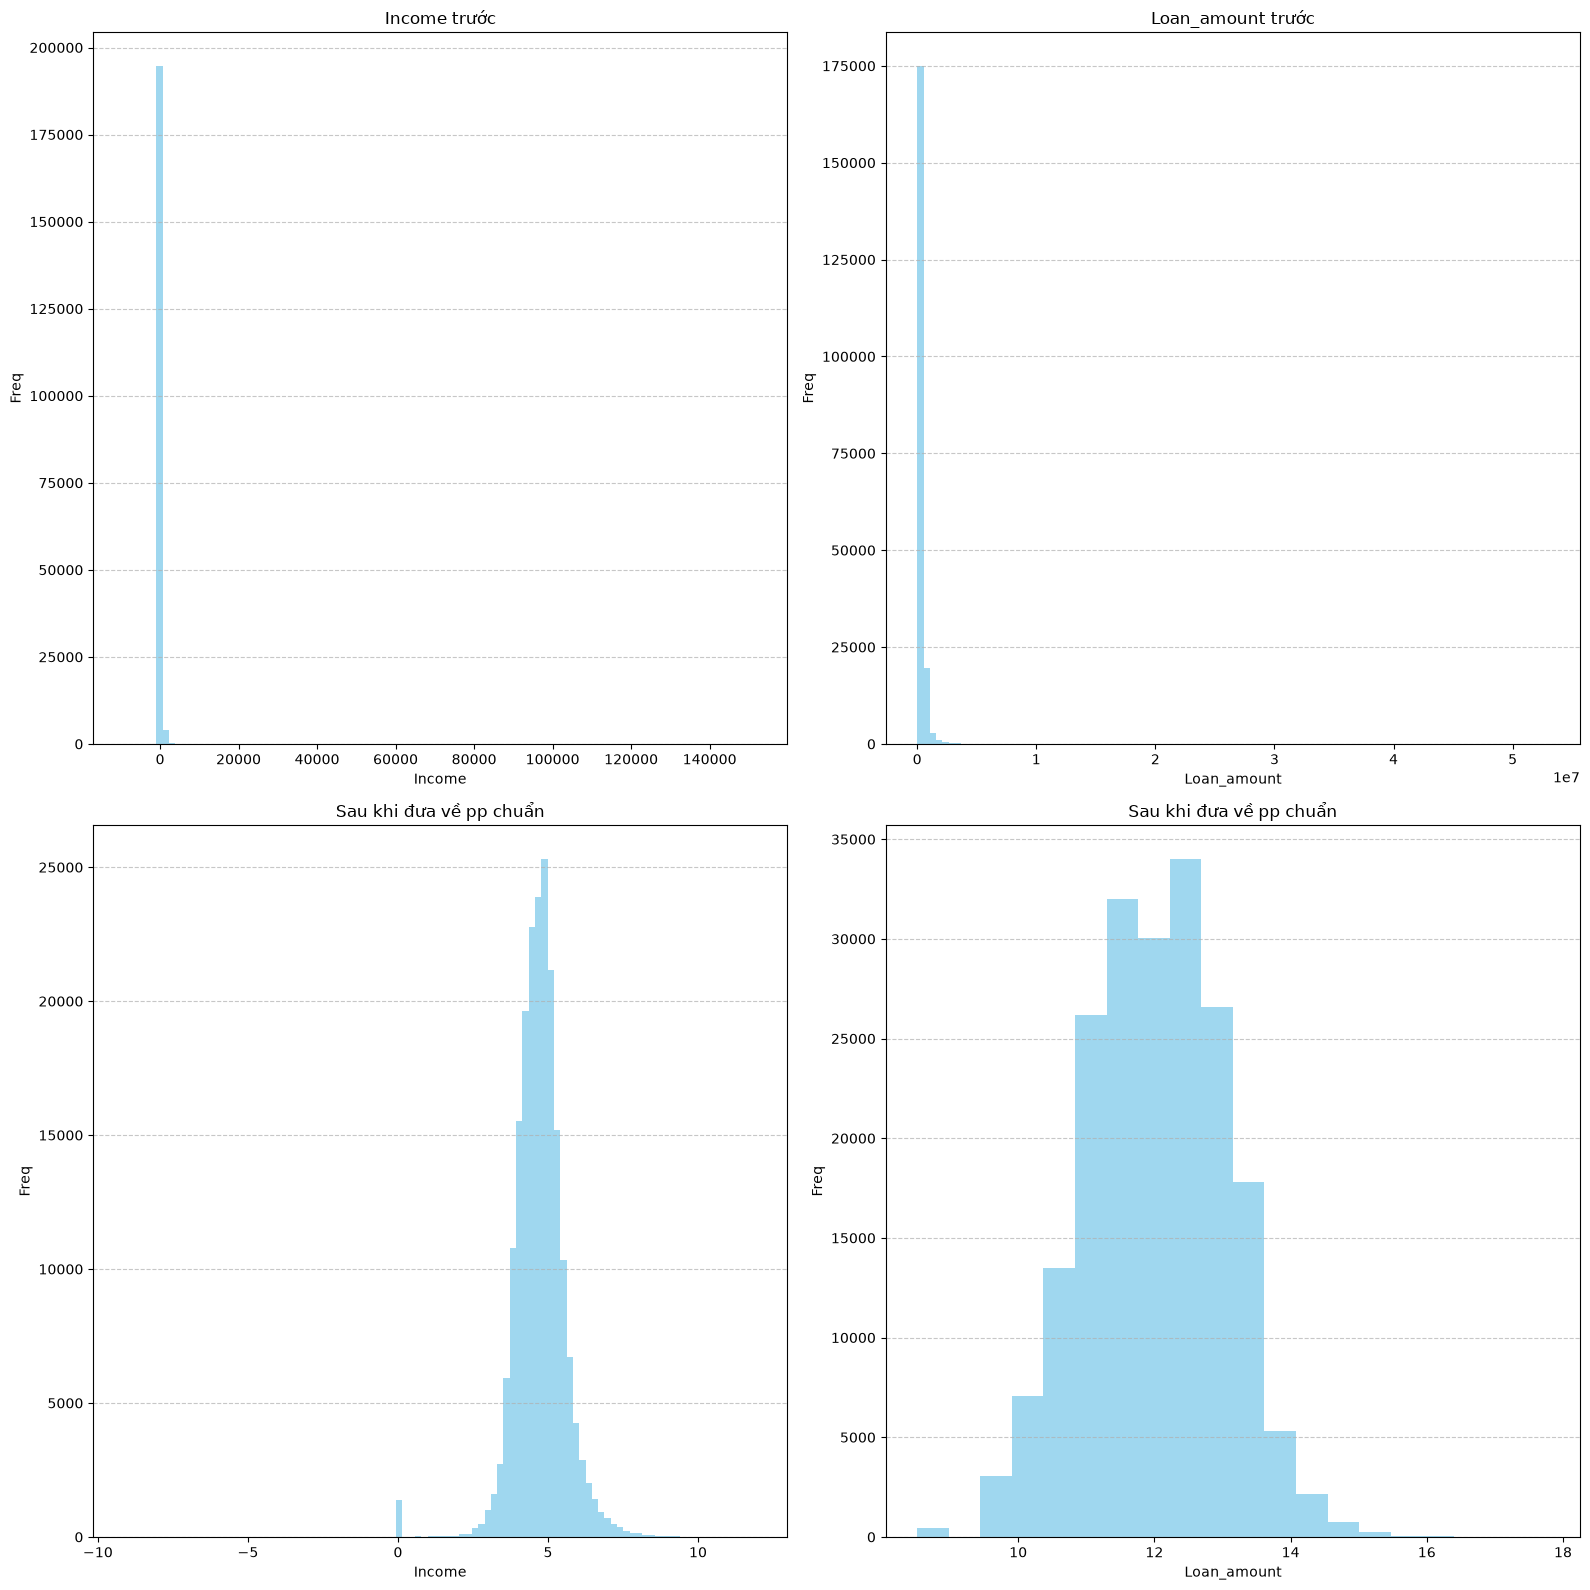

In [115]:

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
bins = 100
axes[0, 0].hist(income_raw_2023, bins=bins, color="skyblue", alpha=0.8)
axes[0, 0].set_title("Income trước")
axes[0, 0].set_xlabel("Income")
axes[0, 0].set_ylabel("Freq")
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

axes[0, 1].hist(loan_amount_raw_2023, bins=bins, color="skyblue", alpha=0.8)
axes[0, 1].set_title("Loan_amount trước")
axes[0, 1].set_xlabel("Loan_amount")
axes[0, 1].set_ylabel("Freq")
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

axes[1, 0].hist(income_processed, bins=bins, color="skyblue", alpha=0.8)
axes[1, 0].set_title("Sau khi đưa về pp chuẩn")
axes[1, 0].set_xlabel("Income")
axes[1, 0].set_ylabel("Freq")
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

axes[1, 1].hist(loan_amount_processed, bins=20, color="skyblue", alpha=0.8)
axes[1, 1].set_title("Sau khi đưa về pp chuẩn")
axes[1, 1].set_xlabel("Loan_amount")
axes[1, 1].set_ylabel("Freq")
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Z ~ -15.28 muy, điều này là 1 việc bất khả thi trong tự nhiên. và nhìn vào biểu đồ, phân phối sẽ xuất hiện một đỉnh nhọn dị biệt tại mốc 0 và một cái đuôi âm bất thường kéo dài tới Z ~ 15.28 muy. điều này vi phạm nghiêm trọng giả định phân phối chuẩn đối xứng cần thiết cho các mô hình hồi quy Logistic Regression. do đó lọc income > 0

In [116]:
income_processed.describe()

count    199299.000000
mean          4.710056
std           0.904646
min          -9.105091
25%           4.262680
50%           4.709530
75%           5.159055
max          11.930266
Name: income, dtype: float64

Đưa về pp chuẩn và lọc

In [117]:
# Cách viết Sign Log: giữ nguyên dấu âm/dương và log trị tuyệt đối
df_2023["income"] = np.sign(df_2023["income"]) * np.log1p(np.abs(df_2023["income"]))
df_2023 = df_2023[df_2023["income"] > 0]
df_2023["loan_amount"] = np.log1p(df_2023["loan_amount"])
df_2024["income"] = np.sign(df_2024["income"]) * np.log1p(np.abs(df_2024["income"]))
df_2024 = df_2024[df_2024["income"] > 0]
df_2024["loan_amount"] = np.log1p(df_2024["loan_amount"])



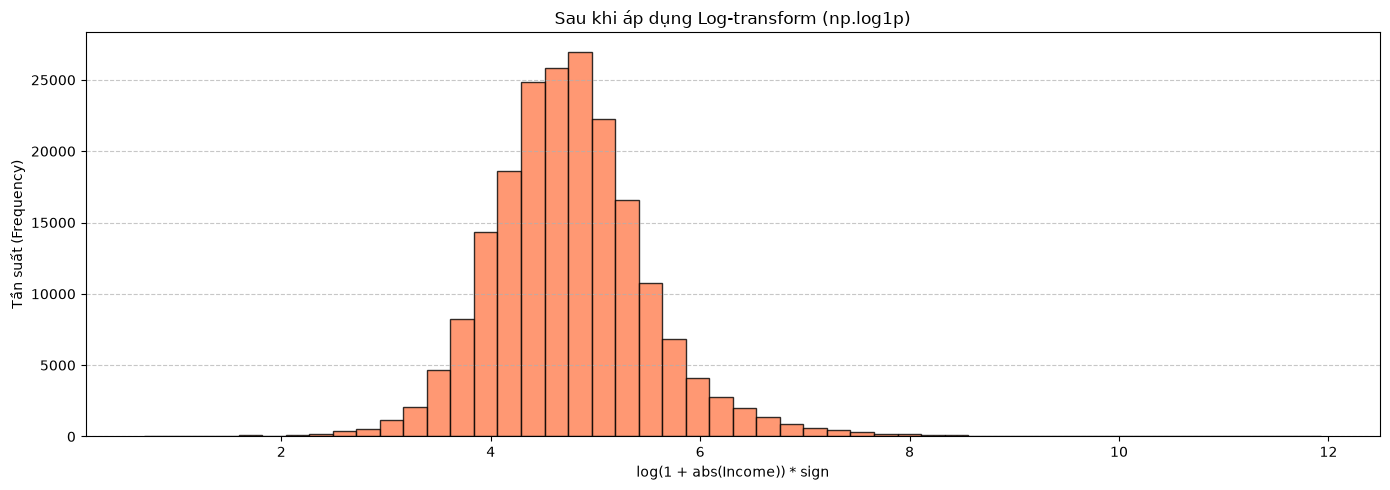

In [118]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 1, figsize=(14, 5))
axes.hist(df_2023["income"], bins=50, color='coral', edgecolor='black', alpha=0.8)
axes.set_title('Sau khi áp dụng Log-transform (np.log1p)')
axes.set_xlabel('log(1 + abs(Income)) * sign')
axes.set_ylabel('Tần suất (Frequency)')
axes.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [120]:
df_2023.to_csv(f"{DATA_DIR}/processed/state_NY_processed_2023.csv",index=False)
df_2024.to_csv(f"{DATA_DIR}/processed/state_NY_processed_2024.csv",index=False)